
# 1.5 Transform validation datasets for ENet zbig models

This notebook replaces the old generic validation transformation with a model-aware ENet zbig transformation.

It does four things:

1. Rebuilds Collection A group matrices exactly like `1. process_collection_a.ipynb`.
2. Finds the saved ENet zbig `.h5` models and the validation proteins that have matching models.
3. Uses the saved z-score normalizer stored inside the ENet zbig model artifacts to transform the validation transcriptomics matrices.
4. Saves a new validation folder for notebook `7.5.test_enet_zbig.ipynb`, and plots raw vs transformed distributions against `transcriptomics_filtered.joblib` and `proteomics_matched.joblib` like `2. comparison.ipynb`.

The main outputs are written to:

```text
../val_data_enet_zbig/
```

The files used by notebook 7.5 are:

```text
LabelFree_transcriptomics.joblib
LabelFree_transcriptomics_raw.joblib
LabelFree_proteomics.joblib
LabelFree_proteomics_raw.joblib

iTRAQ_transcriptomics.joblib
iTRAQ_transcriptomics_raw.joblib
iTRAQ_proteomics.joblib
iTRAQ_proteomics_raw.joblib

TMT_transcriptomics.joblib
TMT_transcriptomics_raw.joblib
TMT_proteomics.joblib
TMT_proteomics_raw.joblib

manifest_enet_zbig_transform.json
normalizer_reference.joblib
matching_proteins_by_dataset.csv
```


In [1]:

from pathlib import Path
import sys

# Make src/utils_val.py importable whether the kernel starts in the project root,
# notebooks, or notebooks2.
CWD = Path.cwd().resolve()
_src_search_roots = []
for _base in [CWD, *CWD.parents]:
    for _candidate in [_base, _base / "notebooks", _base / "notebooks2"]:
        if _candidate not in _src_search_roots:
            _src_search_roots.append(_candidate)

for _candidate in _src_search_roots:
    if (_candidate / "src" / "utils_val.py").exists():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        print("Using validation utilities from:", _candidate / "src" / "utils_val.py")
        break
else:
    print("src/utils_val.py was not found. Fallback helper functions will be used where possible.")

try:
    import src.utils_val as uv
    from src.utils_val import *
except Exception as exc:
    uv = None
    print("Could not import src.utils_val:", type(exc).__name__, exc)


def sync_utils_globals(namespace=None, **kwargs):
    """Push notebook globals into src.utils_val when that module is available."""
    if uv is None:
        return None
    ns = globals() if namespace is None else namespace
    clean = {}
    for _name, _value in dict(ns).items():
        if str(_name).startswith("__"):
            continue
        clean[_name] = _value
    clean.update(kwargs)
    if hasattr(uv, "configure_runtime_globals"):
        uv.configure_runtime_globals(**clean)
    elif hasattr(uv, "set_module_globals"):
        try:
            uv.set_module_globals(clean)
        except TypeError:
            uv.set_module_globals(**clean)
    else:
        for _name, _value in clean.items():
            setattr(uv, _name, _value)
    return None

sync_utils_globals()


Using validation utilities from: C:\Users\hp\Desktop\new_pRNA\notebooks2\src\utils_val.py


In [2]:

import os
import re
import glob
import json
import lzma
import gzip
import zlib
import pickle
import hashlib
import warnings
from pathlib import Path

import h5py
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

# Compatibility shim for some numpy 2 pickles opened in numpy 1.x environments.
try:
    import numpy.core.numeric
    import numpy.core.multiarray
    sys.modules["numpy._core"] = sys.modules.get("numpy.core")
    sys.modules["numpy._core.numeric"] = numpy.core.numeric
    sys.modules["numpy._core.multiarray"] = numpy.core.multiarray
except Exception:
    pass

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 180,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})


In [3]:

# ============================================================
# Configuration
# ============================================================

PROJECT_MARKERS = [
    "data/Collection_A",
    "processed_data",
    "res_enet_zbig",
    "results_enet_zbig",
    "results_enet_xbig",
    "Table0_S1-S8_Combined20220114.xlsx",
]

def _candidate_score(path: Path) -> int:
    score = 0
    for marker in PROJECT_MARKERS:
        if (path / marker).exists():
            score += 1
    return score

_candidates = []
for p in [CWD, *CWD.parents]:
    if p.exists() and p not in _candidates:
        _candidates.append(p)
ROOT_DIR = max(_candidates, key=_candidate_score)

DATA_DIR = ROOT_DIR / "data" / "Collection_A"
PROCESSED_DIR = ROOT_DIR / "processed_data"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

VAL_OUT_DIR = ROOT_DIR / "val_data_enet_zbig"
VAL_OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR = VAL_OUT_DIR / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_DIR_CANDIDATES = [
    ROOT_DIR / "res_enet_zbig",
    ROOT_DIR / "results_enet_zbig",
    ROOT_DIR / "results_enet_xbig",
    ROOT_DIR / "res_enet_xbig",
]
MODEL_DIR = next((p for p in MODEL_DIR_CANDIDATES if p.exists() and any(p.glob("*.h5"))), MODEL_DIR_CANDIDATES[0])
MODEL_SOURCE_LABEL = MODEL_DIR.name

DATASET_PREFIXES = ["LabelFree", "iTRAQ", "TMT"]
GROUPS = DATASET_PREFIXES
TYPES = ["Protein", "RNA"]

# Scan only a subset by default when checking whether all saved model normalizers
# are identical. The actual evaluation notebook still loads each model's own
# normalizer and will fall back to per-model transformation if a mismatch is found.
MAX_MODELS_TO_SCAN_FOR_NORMALIZER_CHECK = 50
STRICT_SHARED_NORMALIZER = False

# Proteomics target transformation mirrors notebook 2.
RNA_TRANSFORM = None
RNA_METHOD = "enet_zbig_saved_zscore"
RNA_CLIP_Q = None

PROT_TRANSFORM = "asinh"
PROT_METHOD_TMT_ITRAQ = "standard_z"
PROT_METHOD_LABELFREE = "robust_z"
LABELFREE_SAMPLE_CENTER = "median"

# Plot sampling to avoid flattening millions of values into a single huge figure.
MAX_VALUES_PER_DISTRIBUTION = 250_000
RANDOM_SEED = 42

print("Current working directory:", CWD)
print("Detected project root:", ROOT_DIR)
print("Collection A input:", DATA_DIR, "exists=", DATA_DIR.exists())
print("Processed data directory:", PROCESSED_DIR)
print("ENet zbig model directory:", MODEL_DIR, "exists=", MODEL_DIR.exists())
print("Validation output directory:", VAL_OUT_DIR)

sync_utils_globals()


Current working directory: C:\Users\hp\Desktop\new_pRNA\notebooks2
Detected project root: C:\Users\hp\Desktop\new_pRNA
Collection A input: C:\Users\hp\Desktop\new_pRNA\data\Collection_A exists= True
Processed data directory: C:\Users\hp\Desktop\new_pRNA\processed_data
ENet zbig model directory: C:\Users\hp\Desktop\new_pRNA\res_enet_zbig exists= True
Validation output directory: C:\Users\hp\Desktop\new_pRNA\val_data_enet_zbig


## 1. Collect Collection A exactly like process_collection_a

In [4]:

# ============================================================
# Collection A cohort grouping copied from 1. process_collection_a.ipynb
# ============================================================

COHORT_GROUPS = {
    "TMT": [
        "colon_2019", "renal_2019", "Endomet_val", "breast2020", "pedbrain_2020",
        "lung_2020_smoke", "lung_val", "lung2021", "headneck_2021", "pancrea2021",
        "brain_2021", "liver_val",
    ],
    "iTRAQ": [
        "breast_2016", "ovary_2016", "stomach_2019",
    ],
    "LabelFree": [
        "brain", "colon", "prostate", "liver", "lung",
    ],
}

# Fallback helpers if src.utils_val is not available.
try:
    filter_nans
except NameError:
    def filter_nans(df, max_nan_fraction=0.50):
        """Drop features/samples with more than max_nan_fraction missing values."""
        if df is None or df.empty:
            return pd.DataFrame()
        out = df.copy()
        out = out.loc[out.isna().mean(axis=1) <= max_nan_fraction]
        out = out.loc[:, out.isna().mean(axis=0) <= max_nan_fraction]
        return out

try:
    standardize_to_ccle_format
except NameError:
    def standardize_to_ccle_format(df):
        """Simple fallback: force string labels and numeric values, keeping samples as rows."""
        out = df.copy()
        out.index = out.index.astype(str)
        out.columns = out.columns.astype(str)
        out = out.apply(pd.to_numeric, errors="coerce")
        return out

try:
    fit_on_ref_apply
except NameError:
    from sklearn.preprocessing import StandardScaler, RobustScaler

    def _sample_center_df(df, how="median"):
        if how is None:
            return df
        if how == "median":
            return df.sub(df.median(axis=1), axis=0)
        if how == "mean":
            return df.sub(df.mean(axis=1), axis=0)
        return df

    def fit_on_ref_apply(df_target, df_ref, method="standard_z", transform=None,
                         clip_nonneg=False, sample_center=None, clip_to_ref_quantiles=None):
        common = [c for c in df_ref.columns if c in df_target.columns]
        if not common:
            return None, None, []
        ref = df_ref[common].astype(float).copy()
        tgt = df_target[common].astype(float).copy()
        if clip_nonneg:
            ref = ref.clip(lower=0)
            tgt = tgt.clip(lower=0)
        if transform == "log2p1":
            ref = np.log2(ref + 1.0)
            tgt = np.log2(tgt + 1.0)
        elif transform == "asinh":
            ref = np.arcsinh(ref)
            tgt = np.arcsinh(tgt)
        if clip_to_ref_quantiles is not None:
            lo, hi = clip_to_ref_quantiles
            qlo = ref.quantile(lo)
            qhi = ref.quantile(hi)
            tgt = tgt.clip(lower=qlo, upper=qhi, axis=1)
        tgt = _sample_center_df(tgt, sample_center)
        scaler = RobustScaler() if method == "robust_z" else StandardScaler()
        scaler.fit(ref)
        arr = scaler.transform(tgt)
        out = pd.DataFrame(arr, index=tgt.index, columns=common)
        return out, scaler, common


In [5]:

# ============================================================
# Load, concatenate, filter, transpose, and save Collection A group matrices
# ============================================================

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Collection A directory was not found: {DATA_DIR}")

group_data = {g: {"prot": [], "rna": []} for g in COHORT_GROUPS}
subdirs = [f.path for f in os.scandir(DATA_DIR) if f.is_dir()]
print(f"Found {len(subdirs)} subdirectories in {DATA_DIR}")

for subdir in tqdm(subdirs, desc="Processing Collection A cohorts"):
    cohort_name = os.path.basename(subdir)

    assigned_group = None
    for group_name, cohort_list in COHORT_GROUPS.items():
        if cohort_name in cohort_list:
            assigned_group = group_name
            break

    if assigned_group is None:
        print(f"[WARNING] Cohort '{cohort_name}' not in defined groups. Skipping.")
        continue

    prot_files = glob.glob(os.path.join(subdir, "protein_matrix_*.txt"))
    rna_files = glob.glob(os.path.join(subdir, "RNA_matrix_*.txt"))

    if not prot_files or not rna_files:
        print(f"[WARNING] Missing protein/RNA files for {cohort_name}. Skipping.")
        continue

    try:
        df_p = pd.read_csv(prot_files[0], sep="\t", index_col=0)
        df_r = pd.read_csv(rna_files[0], sep="\t", index_col=0)

        common_samples = df_p.columns.intersection(df_r.columns)
        if len(common_samples) == 0:
            print(f"[WARNING] No matched samples for {cohort_name}. Skipping.")
            continue

        df_p = df_p[common_samples]
        df_r = df_r[common_samples]

        new_names = [f"{cohort_name.upper()}_{i+1}" for i in range(len(common_samples))]
        df_p.columns = new_names
        df_r.columns = new_names

        group_data[assigned_group]["prot"].append(df_p)
        group_data[assigned_group]["rna"].append(df_r)

    except Exception as exc:
        print(f"  -> ERROR in {cohort_name}: {type(exc).__name__}: {exc}")

# Map RNA Ensembl ids to gene symbols using the same metadata file used before.
MAPPING_FILE = DATA_DIR / "brain" / "rows_metadata.csv"
print("RNA mapping file:", MAPPING_FILE, "exists=", MAPPING_FILE.exists())

processed_groups = {}
for group_name, dfs in group_data.items():
    print(f"\n=== Processing Group: {group_name} ===")
    full_protein = pd.concat(dfs["prot"], axis=1, join="outer", sort=True) if dfs["prot"] else pd.DataFrame()
    full_rna = pd.concat(dfs["rna"], axis=1, join="outer", sort=True) if dfs["rna"] else pd.DataFrame()

    if MAPPING_FILE.exists() and not full_rna.empty:
        try:
            map_df = pd.read_csv(MAPPING_FILE)
            map_df = map_df.dropna(subset=["ensembl_gene_id", "gene_symbol"])
            id2sym = dict(zip(map_df["ensembl_gene_id"], map_df["gene_symbol"]))
            full_rna.index = full_rna.index.map(lambda x: id2sym.get(x, x))
            if full_rna.index.duplicated().any():
                print(f"   -> Found {full_rna.index.duplicated().sum()} duplicate RNA symbols. Averaging...")
                full_rna = full_rna.groupby(level=0).mean()
            print("   -> RNA id-to-symbol mapping complete.")
        except Exception as exc:
            print(f"   -> RNA mapping error: {type(exc).__name__}: {exc}")

    if full_protein.empty or full_rna.empty:
        print(" [WARNING] Missing protein or RNA data after concatenation; skipping group.")
        continue

    print(f" Initial shapes -> Protein: {full_protein.shape}, RNA: {full_rna.shape}")
    full_protein = filter_nans(full_protein)
    full_rna = filter_nans(full_rna)

    integrated_protein = full_protein.T
    integrated_rna = full_rna.T
    integrated_protein = integrated_protein.loc[~integrated_protein.index.duplicated(keep="first")]
    integrated_rna = integrated_rna.loc[~integrated_rna.index.duplicated(keep="first")]

    integrated_protein = standardize_to_ccle_format(integrated_protein)
    integrated_rna = standardize_to_ccle_format(integrated_rna)

    processed_groups[group_name] = {"Protein": integrated_protein, "RNA": integrated_rna}

    p_out = PROCESSED_DIR / f"Collection_A_{group_name}_Protein.csv"
    r_out = PROCESSED_DIR / f"Collection_A_{group_name}_RNA.csv"
    integrated_protein.to_csv(p_out)
    integrated_rna.to_csv(r_out)

    print(f" Final shapes   -> Protein: {integrated_protein.shape}, RNA: {integrated_rna.shape}")
    print(f" Saved to {p_out} and {r_out}")
    display(integrated_protein.head())
    display(integrated_rna.head())

if not processed_groups:
    raise RuntimeError("No Collection A groups were processed successfully.")


Found 20 subdirectories in C:\Users\hp\Desktop\new_pRNA\data\Collection_A


Processing Collection A cohorts:   0%|          | 0/20 [00:00<?, ?it/s]

RNA mapping file: C:\Users\hp\Desktop\new_pRNA\data\Collection_A\brain\rows_metadata.csv exists= True

=== Processing Group: TMT ===
   -> Found 714 duplicate RNA symbols. Averaging...
   -> RNA id-to-symbol mapping complete.
 Initial shapes -> Protein: (11259, 1924), RNA: (32840, 1924)
   -> Dropped 4374 Features & 0 Samples
   -> Dropped 17839 Features & 0 Samples


Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed
4 input query terms found no hit:	['ENSG00000112096', 'ENSG00000130723', 'ENSG00000148362', 'ENSG00000274791']


 Final shapes   -> Protein: (1924, 6885), RNA: (1924, 15001)
 Saved to C:\Users\hp\Desktop\new_pRNA\processed_data\Collection_A_TMT_Protein.csv and C:\Users\hp\Desktop\new_pRNA\processed_data\Collection_A_TMT_RNA.csv


ensembl_gene_id,A1BG,A2M,AAAS,AACS,AAGAB,AAK1,AAMDC,AAMP,AAR2,AARS1,...,ZNRD2,ZNRF2,ZPR1,ZRANB2,ZSCAN18,ZSWIM8,ZW10,ZYG11B,ZYX,ZZEF1
BRAIN_2021_1,0.078,0.487,-0.254,-0.144,-0.467,-0.090,-0.079,0.330,-0.265,-0.318,...,-0.015,-0.469,-0.038,0.160,0.660,-0.047,-0.106,0.079,-0.785,-0.488
BRAIN_2021_2,-0.146,0.799,0.184,-0.471,0.245,-0.610,0.119,-0.087,0.385,0.134,...,-0.362,0.010,0.182,0.077,-1.272,0.162,-0.213,0.049,0.138,-0.290
BRAIN_2021_3,0.822,1.096,-0.094,-0.106,-0.248,0.014,-0.700,-0.638,0.593,-0.367,...,0.130,-0.437,0.298,-0.795,-0.165,-0.066,-0.307,-0.172,0.012,-0.132
BRAIN_2021_4,-0.065,0.129,0.048,-0.118,0.304,0.322,-0.555,-0.363,0.365,0.595,...,0.652,-0.259,-0.245,-1.056,-0.600,-0.255,0.464,0.178,-0.720,-0.150
BRAIN_2021_5,-0.764,-1.032,-0.217,-0.696,-0.052,0.345,-0.643,0.069,0.347,-0.325,...,-0.272,-0.644,-0.081,0.160,-0.752,-0.093,0.011,0.113,1.005,-0.230


... (7 outputs left out)

Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed
1 input query terms found no hit:	['ENSG00000112096']


 Final shapes   -> Protein: (360, 2563), RNA: (360, 14947)
 Saved to C:\Users\hp\Desktop\new_pRNA\processed_data\Collection_A_LabelFree_Protein.csv and C:\Users\hp\Desktop\new_pRNA\processed_data\Collection_A_LabelFree_RNA.csv


,A1BG,A2M,AARS1,AARS2,AASDHPPT,ABAT,ABCB7,ABCD3,ABCE1,ABCF1,...,YWHAQ,YWHAZ,ZC3H15,ZC3HAV1,ZFR,ZMPSTE24,ZNF207,ZW10,ZYX,ZZEF1
BRAIN_1,6.98,9.435,9.745,7.422,8.581,10.012,6.823,8.329,8.591,7.380,...,10.229,10.932,6.982,NaN,7.000,7.935,7.035,7.435,8.098,7.567
BRAIN_2,6.98,9.790,9.747,7.852,8.584,10.301,7.927,8.948,8.481,8.053,...,10.416,10.698,6.982,NaN,8.187,7.665,8.568,7.599,8.641,7.569
BRAIN_3,6.98,9.794,9.816,7.706,8.695,9.891,7.827,8.781,8.706,8.444,...,10.215,10.946,7.768,NaN,7.000,7.910,7.035,7.830,8.226,7.615
BRAIN_4,6.98,9.633,9.712,7.676,8.641,10.365,7.727,8.860,8.228,8.164,...,10.155,10.849,6.982,NaN,7.000,8.016,7.035,7.774,8.294,7.639
BRAIN_5,6.98,9.631,9.790,7.770,9.113,10.262,7.893,8.639,8.248,8.169,...,10.104,10.918,7.737,NaN,7.000,8.031,7.817,7.912,8.098,7.641


,A1BG,A1CF,A2LD1,A2M,A4GALT,AAAS,AACS,AADAT,AAGAB,AAK1,...,ZW10,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11B,ZYX,ZZEF1,ZZZ3
BRAIN_1,12.893,NaN,0.826,21.054,NaN,4.548,2.540,3.030,10.040,1.686,...,2.241,2.650,2.489,0.805,2.664,0.600,11.526,11.135,1.012,1.781
BRAIN_2,8.307,NaN,0.939,20.753,NaN,9.086,1.035,0.474,10.601,2.372,...,3.313,2.422,0.679,1.019,2.700,1.964,10.713,35.617,2.349,1.895
BRAIN_3,15.115,NaN,0.770,18.468,NaN,3.590,2.796,2.194,8.735,1.446,...,1.143,1.566,1.440,0.422,0.939,0.278,6.985,8.945,0.497,1.029
BRAIN_4,2.053,NaN,0.751,35.283,NaN,4.274,2.869,1.592,17.248,5.144,...,3.184,1.881,3.975,0.663,3.019,0.717,15.983,10.402,2.042,2.123
BRAIN_5,6.533,NaN,1.110,29.215,NaN,5.186,1.586,2.978,10.827,1.595,...,2.893,1.973,2.196,0.839,2.132,0.863,6.988,6.625,1.148,1.810


## 2. Load CCLE references and build raw validation stores

In [6]:

# ============================================================
# Load reference CCLE matrices and raw Collection A matrices
# ============================================================

CCLE_RNA_PATH = PROCESSED_DIR / "transcriptomics_filtered.joblib"
CCLE_PROT_PATH = PROCESSED_DIR / "proteomics_matched.joblib"

if not CCLE_RNA_PATH.exists():
    raise FileNotFoundError(f"Missing CCLE transcriptomics reference: {CCLE_RNA_PATH}")
if not CCLE_PROT_PATH.exists():
    raise FileNotFoundError(f"Missing CCLE proteomics reference: {CCLE_PROT_PATH}")

ccle_rna = joblib.load(CCLE_RNA_PATH)
ccle_prot = joblib.load(CCLE_PROT_PATH)
ccle_rna = standardize_to_ccle_format(ccle_rna)
ccle_prot = standardize_to_ccle_format(ccle_prot)

print("CCLE transcriptomics_filtered:", ccle_rna.shape)
print("CCLE proteomics_matched:", ccle_prot.shape)

# data_store mirrors notebook 2: samples x features for each validation group.
data_store = {}
for group in GROUPS:
    data_store[group] = {}
    for dtype in TYPES:
        if group in processed_groups and dtype in processed_groups[group]:
            df = processed_groups[group][dtype].copy()
        else:
            path = PROCESSED_DIR / f"Collection_A_{group}_{dtype}.csv"
            df = pd.read_csv(path, index_col=0) if path.exists() else None
            if df is not None:
                df = standardize_to_ccle_format(df)
        data_store[group][dtype] = df
        print(f"{group:9s} {dtype:7s}:", None if df is None else df.shape)

sync_utils_globals()


CCLE transcriptomics_filtered: (369, 22614)
CCLE proteomics_matched: (369, 5113)
LabelFree Protein: (360, 2563)
LabelFree RNA    : (360, 14947)
iTRAQ     Protein: (276, 4994)
iTRAQ     RNA    : (276, 14521)
TMT       Protein: (1924, 6885)
TMT       RNA    : (1924, 15001)


## 3. Discover ENet zbig models and matching validation proteins

In [7]:

# ============================================================
# Saved model discovery
# ============================================================

def parse_model_filename(path):
    """Parse names like A2M_enet_8020_zscore_fast_k5000.h5."""
    path = Path(path)
    stem = path.stem
    parts = stem.split("_")
    family_idx = None
    for i, token in enumerate(parts):
        if token.lower() in {"enet", "xgb"}:
            family_idx = i
            break
    if family_idx is None:
        return stem, None, None, None, np.nan
    protein = "_".join(parts[:family_idx])
    family = parts[family_idx].lower()
    rest = parts[family_idx + 1:]
    norm = None
    grid = None
    k = np.nan
    if rest and rest[0] == "8020":
        rest = rest[1:]
    if rest:
        norm = rest[0]
    if len(rest) >= 2:
        grid = rest[1]
    for token in rest:
        m = re.match(r"k(\d+)$", str(token), flags=re.IGNORECASE)
        if m:
            k = int(m.group(1))
            break
    return protein, family, norm, grid, k

if not MODEL_DIR.exists():
    raise FileNotFoundError(f"Model directory does not exist: {MODEL_DIR}")

model_files = []
for p in sorted(MODEL_DIR.glob("*.h5")):
    protein, family, norm, grid, k = parse_model_filename(p)
    if family is not None and family.lower() != "enet":
        continue
    model_files.append({
        "source_folder": MODEL_SOURCE_LABEL,
        "h5_path": str(p),
        "file": p.name,
        "protein": protein,
        "model_family": family,
        "normalization": norm,
        "grid_preset": grid,
        "select_k": k,
        "file_size_mb": p.stat().st_size / (1024 ** 2),
    })

model_inventory = pd.DataFrame(model_files)
if model_inventory.empty:
    raise FileNotFoundError(f"No ENet .h5 model files found in {MODEL_DIR}")

model_inventory["run_label"] = model_inventory.apply(
    lambda r: f"{r['source_folder']} | {r['normalization']} | {r['grid_preset']} | k{int(r['select_k']) if pd.notna(r['select_k']) else 'NA'}",
    axis=1,
)
model_inventory.to_csv(VAL_OUT_DIR / "enet_zbig_model_inventory.csv", index=False)

print("Models found:", len(model_inventory))
print("Unique model proteins:", model_inventory["protein"].nunique())
display(model_inventory.head())
display(model_inventory.groupby("run_label").agg(models=("file", "count"), proteins=("protein", "nunique")).sort_values("models", ascending=False))


Models found: 5113
Unique model proteins: 5113


,source_folder,h5_path,file,protein,model_family,normalization,grid_preset,select_k,file_size_mb,run_label
0,res_enet_zbig,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\A2M...,A2M_enet_8020_zscore_fast_k5000.h5,A2M,enet,zscore,fast,5000,0.283202,res_enet_zbig | zscore | fast | k5000
1,res_enet_zbig,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\AAA...,AAAS_enet_8020_zscore_fast_k5000.h5,AAAS,enet,zscore,fast,5000,0.284116,res_enet_zbig | zscore | fast | k5000
2,res_enet_zbig,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\AAC...,AACS_enet_8020_zscore_fast_k5000.h5,AACS,enet,zscore,fast,5000,0.284033,res_enet_zbig | zscore | fast | k5000
3,res_enet_zbig,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\AAG...,AAGAB_enet_8020_zscore_fast_k5000.h5,AAGAB,enet,zscore,fast,5000,0.281512,res_enet_zbig | zscore | fast | k5000
4,res_enet_zbig,C:\Users\hp\Desktop\new_pRNA\res_enet_zbig\AAK...,AAK1_enet_8020_zscore_fast_k5000.h5,AAK1,enet,zscore,fast,5000,0.281770,res_enet_zbig | zscore | fast | k5000


,models,proteins
run_label,,
res_enet_zbig | zscore | fast | k5000,5113,5113


In [8]:

# ============================================================
# Restrict validation proteomics to proteins with saved ENet zbig models
# ============================================================

model_proteins = set(model_inventory["protein"].astype(str))
ccle_proteins = set(ccle_prot.columns.astype(str))
matching_rows = []
matching_proteins_by_dataset = {}

for group in GROUPS:
    prot = data_store[group].get("Protein")
    if prot is None or prot.empty:
        matching_proteins_by_dataset[group] = []
        continue
    proteins = set(prot.columns.astype(str))
    matching = sorted(proteins.intersection(model_proteins).intersection(ccle_proteins))
    matching_proteins_by_dataset[group] = matching
    matching_rows.append({
        "dataset": group,
        "validation_proteins": len(proteins),
        "model_proteins": len(model_proteins),
        "ccle_reference_proteins": len(ccle_proteins),
        "matching_proteins": len(matching),
    })

matching_summary = pd.DataFrame(matching_rows)
matching_summary.to_csv(VAL_OUT_DIR / "matching_proteins_by_dataset.csv", index=False)

for group, proteins in matching_proteins_by_dataset.items():
    with open(VAL_OUT_DIR / f"{group}_matching_enet_zbig_proteins.txt", "w") as f:
        for protein in proteins:
            f.write(f"{protein}\n")

print("Matching proteins by dataset:")
display(matching_summary)


Matching proteins by dataset:


,dataset,validation_proteins,model_proteins,ccle_reference_proteins,matching_proteins
0,LabelFree,2563,5113,5113,2172
1,iTRAQ,4994,5113,5113,3725
2,TMT,6885,5113,5113,4450


## 4. Unpack ENet zbig H5 normalizer parameters

In [9]:

# ============================================================
# H5 artifact unpacking and z-score normalizer helpers
# ============================================================

def _decode_h5_bytes(x):
    arr = np.asarray(x)
    if arr.dtype.kind in {"S", "a"}:
        return b"".join(arr.astype("S").tolist())
    if arr.dtype == np.uint8:
        return arr.tobytes()
    if arr.shape == ():
        val = arr.item()
        if isinstance(val, bytes):
            return val
        return str(val).encode("utf-8")
    return arr.tobytes()


def _try_unpickle_bytes(raw):
    attempts = [
        ("lzma", lambda b: pickle.loads(lzma.decompress(b))),
        ("gzip", lambda b: pickle.loads(gzip.decompress(b))),
        ("zlib", lambda b: pickle.loads(zlib.decompress(b))),
        ("raw_pickle", lambda b: pickle.loads(b)),
    ]
    errors = []
    for name, fn in attempts:
        try:
            return name, fn(raw)
        except Exception as exc:
            errors.append((name, type(exc).__name__, str(exc)[:160]))
    raise ValueError(f"Could not unpickle artifact. Attempts: {errors}")


def load_h5_artifact(h5_path):
    h5_path = Path(h5_path)
    with h5py.File(h5_path, "r") as f:
        if "model/artifact_pickle_xz" not in f:
            raise KeyError(f"model/artifact_pickle_xz not found in {h5_path}")
        raw = _decode_h5_bytes(f["model/artifact_pickle_xz"][()])
        compression, artifact = _try_unpickle_bytes(raw)
    return artifact


def artifact_get(obj, key, default=None):
    if obj is None:
        return default
    if isinstance(obj, dict) and key in obj:
        return obj[key]
    if hasattr(obj, key):
        return getattr(obj, key)
    return default


def normalizer_from_artifact(artifact):
    normalizer = artifact_get(artifact, "normalizer")
    if normalizer is None:
        return None
    columns = artifact_get(normalizer, "columns")
    mean = artifact_get(normalizer, "mean")
    std = artifact_get(normalizer, "std")
    method = artifact_get(normalizer, "method", artifact_get(artifact, "normalization", None))
    if columns is None or mean is None or std is None:
        return None
    columns = [str(c) for c in list(columns)]
    mean = np.asarray(mean, dtype=np.float64)
    std = np.asarray(std, dtype=np.float64)
    std = np.where(np.isfinite(std) & (std != 0), std, 1.0)
    return {"method": method, "columns": columns, "mean": mean, "std": std}


def normalizer_hash(normalizer, decimals=8):
    if normalizer is None:
        return None
    h = hashlib.sha256()
    for c in normalizer["columns"]:
        h.update(str(c).encode("utf-8"))
        h.update(b"\0")
    h.update(np.round(np.asarray(normalizer["mean"], dtype=np.float64), decimals).tobytes())
    h.update(np.round(np.asarray(normalizer["std"], dtype=np.float64), decimals).tobytes())
    return h.hexdigest()


def apply_saved_zscore_normalizer(X_raw, normalizer, fill_missing_z=0.0):
    """Align raw RNA to saved model-normalizer columns and apply z-score."""
    columns = list(normalizer["columns"])
    mean = pd.Series(np.asarray(normalizer["mean"], dtype=float), index=columns)
    std = pd.Series(np.asarray(normalizer["std"], dtype=float), index=columns).replace(0, 1.0)
    X = X_raw.copy()
    X.columns = X.columns.astype(str)
    X_aligned = X.reindex(columns=columns)
    X_z = (X_aligned - mean) / std
    X_z = X_z.replace([np.inf, -np.inf], np.nan).fillna(fill_missing_z)
    return X_z.astype(np.float32)


In [10]:

# ============================================================
# Select a representative ENet zbig normalizer and check whether model normalizers match
# ============================================================

# Prefer a model whose protein exists in at least one validation dataset.
all_matching_proteins = set().union(*[set(v) for v in matching_proteins_by_dataset.values()]) if matching_proteins_by_dataset else set()
probe_inventory = model_inventory[model_inventory["protein"].isin(all_matching_proteins)].copy()
if probe_inventory.empty:
    probe_inventory = model_inventory.copy()

representative_row = probe_inventory.iloc[0]
representative_artifact = load_h5_artifact(representative_row["h5_path"])
representative_normalizer = normalizer_from_artifact(representative_artifact)
if representative_normalizer is None:
    raise ValueError("The representative ENet zbig model did not contain a readable normalizer.")

representative_hash = normalizer_hash(representative_normalizer)
print("Representative model:", representative_row["file"])
print("Representative protein:", representative_row["protein"])
print("Normalizer method:", representative_normalizer.get("method"))
print("Normalizer columns:", len(representative_normalizer["columns"]))
print("Representative normalizer hash:", representative_hash[:16], "...")

scan_df = probe_inventory.copy()
if MAX_MODELS_TO_SCAN_FOR_NORMALIZER_CHECK is not None:
    scan_df = scan_df.head(int(MAX_MODELS_TO_SCAN_FOR_NORMALIZER_CHECK)).copy()

normalizer_scan_rows = []
for _, row in tqdm(scan_df.iterrows(), total=len(scan_df), desc="Checking normalizer hashes"):
    try:
        art = load_h5_artifact(row["h5_path"])
        norm = normalizer_from_artifact(art)
        h = normalizer_hash(norm)
        normalizer_scan_rows.append({
            "protein": row["protein"],
            "file": row["file"],
            "h5_path": row["h5_path"],
            "normalizer_hash": h,
            "n_columns": len(norm["columns"]) if norm is not None else np.nan,
            "method": norm.get("method") if norm is not None else None,
            "matches_representative": h == representative_hash,
            "error": None,
        })
    except Exception as exc:
        normalizer_scan_rows.append({
            "protein": row["protein"],
            "file": row["file"],
            "h5_path": row["h5_path"],
            "normalizer_hash": None,
            "n_columns": np.nan,
            "method": None,
            "matches_representative": False,
            "error": f"{type(exc).__name__}: {exc}",
        })

normalizer_scan = pd.DataFrame(normalizer_scan_rows)
normalizer_scan.to_csv(VAL_OUT_DIR / "normalizer_scan_summary.csv", index=False)

n_hashes = normalizer_scan["normalizer_hash"].dropna().nunique()
print("Scanned models:", len(normalizer_scan))
print("Unique normalizer hashes in scan:", n_hashes)
display(normalizer_scan.groupby(["normalizer_hash", "matches_representative"], dropna=False).size().to_frame("n_models").reset_index().head(20))

if n_hashes > 1:
    msg = (
        "More than one normalizer hash was found in the scanned ENet zbig models. "
        "Notebook 7.5 will still be correct because it checks each model hash and falls back to "
        "per-model transformation from the raw RNA checkpoint when needed."
    )
    if STRICT_SHARED_NORMALIZER:
        raise ValueError(msg)
    print("WARNING:", msg)

# Save the representative normalizer for inspection and for 7.5 hash matching.
normalizer_reference = {
    "method": representative_normalizer.get("method"),
    "columns": representative_normalizer["columns"],
    "mean": representative_normalizer["mean"],
    "std": representative_normalizer["std"],
    "hash": representative_hash,
    "source_file": representative_row["file"],
    "source_h5_path": representative_row["h5_path"],
}
joblib.dump(normalizer_reference, VAL_OUT_DIR / "normalizer_reference.joblib")

normalizer_preview = pd.DataFrame({
    "gene": representative_normalizer["columns"],
    "zscore_mean": representative_normalizer["mean"],
    "zscore_std": representative_normalizer["std"],
})
normalizer_preview.to_csv(VAL_OUT_DIR / "normalizer_reference_table.csv", index=False)
display(normalizer_preview.head(20))


Representative model: A2M_enet_8020_zscore_fast_k5000.h5
Representative protein: A2M
Normalizer method: zscore
Normalizer columns: 22614
Representative normalizer hash: c3a17d807495060f ...


Checking normalizer hashes:   0%|          | 0/50 [00:00<?, ?it/s]

Scanned models: 50
Unique normalizer hashes in scan: 1


,normalizer_hash,matches_representative,n_models
0,c3a17d807495060fc7670124a8f6f8eb2c9a351aef5a23...,True,50


,gene,zscore_mean,zscore_std
0,A1BG,2.825201,2.050384
1,A1BG-AS1,1.831422,1.317057
2,A1CF,0.327555,0.977727
3,A2M,0.885021,1.803062
4,A2ML1,0.294572,0.851278
5,A4GALT,2.107697,1.550074
6,AAAS,5.692730,0.508165
7,AACS,4.198406,0.717382
8,AACSP1,0.415830,0.752648
9,AADAC,0.702714,1.307849


## 5. Transform and save datasets for notebook 7.5

In [11]:

# ============================================================
# Save transformed validation datasets
# ============================================================

transformed_store = {}
manifest = {
    "created_by": "1.5.transform_enet_zbig.ipynb",
    "model_dir": str(MODEL_DIR),
    "model_source_label": MODEL_SOURCE_LABEL,
    "representative_normalizer_hash": representative_hash,
    "representative_normalizer_file": representative_row["file"],
    "normalizer_scan_unique_hash_count": int(n_hashes),
    "normalizer_scan_n_models": int(len(normalizer_scan)),
    "transcriptomics_are_enet_zbig_zscored": True,
    "proteomics_transform": {
        "LabelFree": {"method": PROT_METHOD_LABELFREE, "transform": PROT_TRANSFORM, "sample_center": LABELFREE_SAMPLE_CENTER},
        "TMT": {"method": PROT_METHOD_TMT_ITRAQ, "transform": PROT_TRANSFORM, "sample_center": None},
        "iTRAQ": {"method": PROT_METHOD_TMT_ITRAQ, "transform": PROT_TRANSFORM, "sample_center": None},
    },
    "datasets": {},
}

for group in GROUPS:
    print(f"\n=== Transforming {group} ===")
    rna_raw = data_store[group].get("RNA")
    prot_raw = data_store[group].get("Protein")
    if rna_raw is None or rna_raw.empty or prot_raw is None or prot_raw.empty:
        print("Skipping: missing RNA or protein data.")
        continue

    # Align samples first.
    common_samples = rna_raw.index.intersection(prot_raw.index)
    rna_raw = rna_raw.loc[common_samples].copy()
    prot_raw = prot_raw.loc[common_samples].copy()

    # Protein targets: restrict to proteins with saved ENet zbig models and fit-on-CCLE transform like notebook 2.
    matching_proteins = matching_proteins_by_dataset.get(group, [])
    if not matching_proteins:
        print("WARNING: no matching proteins for", group)
        continue

    prot_raw_matched = prot_raw.reindex(columns=matching_proteins)
    ccle_prot_matched = ccle_prot.reindex(columns=matching_proteins)

    if group == "LabelFree":
        prot_method = PROT_METHOD_LABELFREE
        sample_center = LABELFREE_SAMPLE_CENTER
    else:
        prot_method = PROT_METHOD_TMT_ITRAQ
        sample_center = None

    prot_transformed, prot_scaler, prot_common = fit_on_ref_apply(
        df_target=prot_raw_matched,
        df_ref=ccle_prot_matched,
        method=prot_method,
        transform=PROT_TRANSFORM,
        clip_nonneg=False,
        sample_center=sample_center,
        clip_to_ref_quantiles=None,
    )
    if prot_transformed is None:
        raise ValueError(f"Protein transformation failed for {group}: no common proteins with CCLE reference.")
    prot_transformed = prot_transformed.reindex(index=common_samples)

    # RNA inputs: use saved ENet zbig z-score normalizer from H5 artifact.
    rna_z = apply_saved_zscore_normalizer(rna_raw, representative_normalizer, fill_missing_z=0.0)

    # Save both raw and transformed versions. 7.5 will use transformed RNA when
    # the model normalizer hash matches; otherwise it falls back to raw and applies
    # that model's own normalizer on the fly.
    joblib.dump(rna_z, VAL_OUT_DIR / f"{group}_transcriptomics.joblib")
    joblib.dump(rna_raw, VAL_OUT_DIR / f"{group}_transcriptomics_raw.joblib")
    joblib.dump(prot_transformed, VAL_OUT_DIR / f"{group}_proteomics.joblib")
    joblib.dump(prot_raw_matched, VAL_OUT_DIR / f"{group}_proteomics_raw.joblib")

    transformed_store[group] = {
        "RNA": rna_z,
        "RNA_raw": rna_raw,
        "Protein": prot_transformed,
        "Protein_raw": prot_raw_matched,
    }

    manifest["datasets"][group] = {
        "n_samples": int(len(common_samples)),
        "raw_rna_shape": list(rna_raw.shape),
        "transformed_rna_shape": list(rna_z.shape),
        "raw_protein_shape": list(prot_raw_matched.shape),
        "transformed_protein_shape": list(prot_transformed.shape),
        "matching_proteins": int(len(matching_proteins)),
        "protein_transform_method": prot_method,
        "protein_transform": PROT_TRANSFORM,
        "protein_sample_center": sample_center,
        "rna_missing_genes_vs_normalizer": int(len(set(representative_normalizer["columns"]) - set(rna_raw.columns.astype(str)))),
    }

    print("Saved:")
    print(" -", VAL_OUT_DIR / f"{group}_transcriptomics.joblib", rna_z.shape)
    print(" -", VAL_OUT_DIR / f"{group}_transcriptomics_raw.joblib", rna_raw.shape)
    print(" -", VAL_OUT_DIR / f"{group}_proteomics.joblib", prot_transformed.shape)
    print(" -", VAL_OUT_DIR / f"{group}_proteomics_raw.joblib", prot_raw_matched.shape)

with open(VAL_OUT_DIR / "manifest_enet_zbig_transform.json", "w") as f:
    json.dump(manifest, f, indent=2)

print("\nSaved manifest:", VAL_OUT_DIR / "manifest_enet_zbig_transform.json")
display(pd.DataFrame(manifest["datasets"]).T)



=== Transforming LabelFree ===
Saved:
 - C:\Users\hp\Desktop\new_pRNA\val_data_enet_zbig\LabelFree_transcriptomics.joblib (360, 22614)
 - C:\Users\hp\Desktop\new_pRNA\val_data_enet_zbig\LabelFree_transcriptomics_raw.joblib (360, 14947)
 - C:\Users\hp\Desktop\new_pRNA\val_data_enet_zbig\LabelFree_proteomics.joblib (360, 2172)
 - C:\Users\hp\Desktop\new_pRNA\val_data_enet_zbig\LabelFree_proteomics_raw.joblib (360, 2172)

=== Transforming iTRAQ ===
Saved:
 - C:\Users\hp\Desktop\new_pRNA\val_data_enet_zbig\iTRAQ_transcriptomics.joblib (276, 22614)
 - C:\Users\hp\Desktop\new_pRNA\val_data_enet_zbig\iTRAQ_transcriptomics_raw.joblib (276, 14521)
 - C:\Users\hp\Desktop\new_pRNA\val_data_enet_zbig\iTRAQ_proteomics.joblib (276, 3725)
 - C:\Users\hp\Desktop\new_pRNA\val_data_enet_zbig\iTRAQ_proteomics_raw.joblib (276, 3725)

=== Transforming TMT ===
Saved:
 - C:\Users\hp\Desktop\new_pRNA\val_data_enet_zbig\TMT_transcriptomics.joblib (1924, 22614)
 - C:\Users\hp\Desktop\new_pRNA\val_data_enet_zbi

,n_samples,raw_rna_shape,transformed_rna_shape,raw_protein_shape,transformed_protein_shape,matching_proteins,protein_transform_method,protein_transform,protein_sample_center,rna_missing_genes_vs_normalizer
LabelFree,360,"[360, 14947]","[360, 22614]","[360, 2172]","[360, 2172]",2172,robust_z,asinh,median,9941
iTRAQ,276,"[276, 14521]","[276, 22614]","[276, 3725]","[276, 3725]",3725,standard_z,asinh,None,10234
TMT,1924,"[1924, 15001]","[1924, 22614]","[1924, 4450]","[1924, 4450]",4450,standard_z,asinh,None,9781


## 6. Plot raw vs transformed distributions against CCLE references

Zoom limits from quantiles 0.005-0.995: [-0.7240, 79.8150]
Rows before zoom: 1,000,000; after zoom: 990,001
Zoom limits from quantiles 0.005-0.995: [-5.4516, 50.9713]
Rows before zoom: 1,000,000; after zoom: 990,000


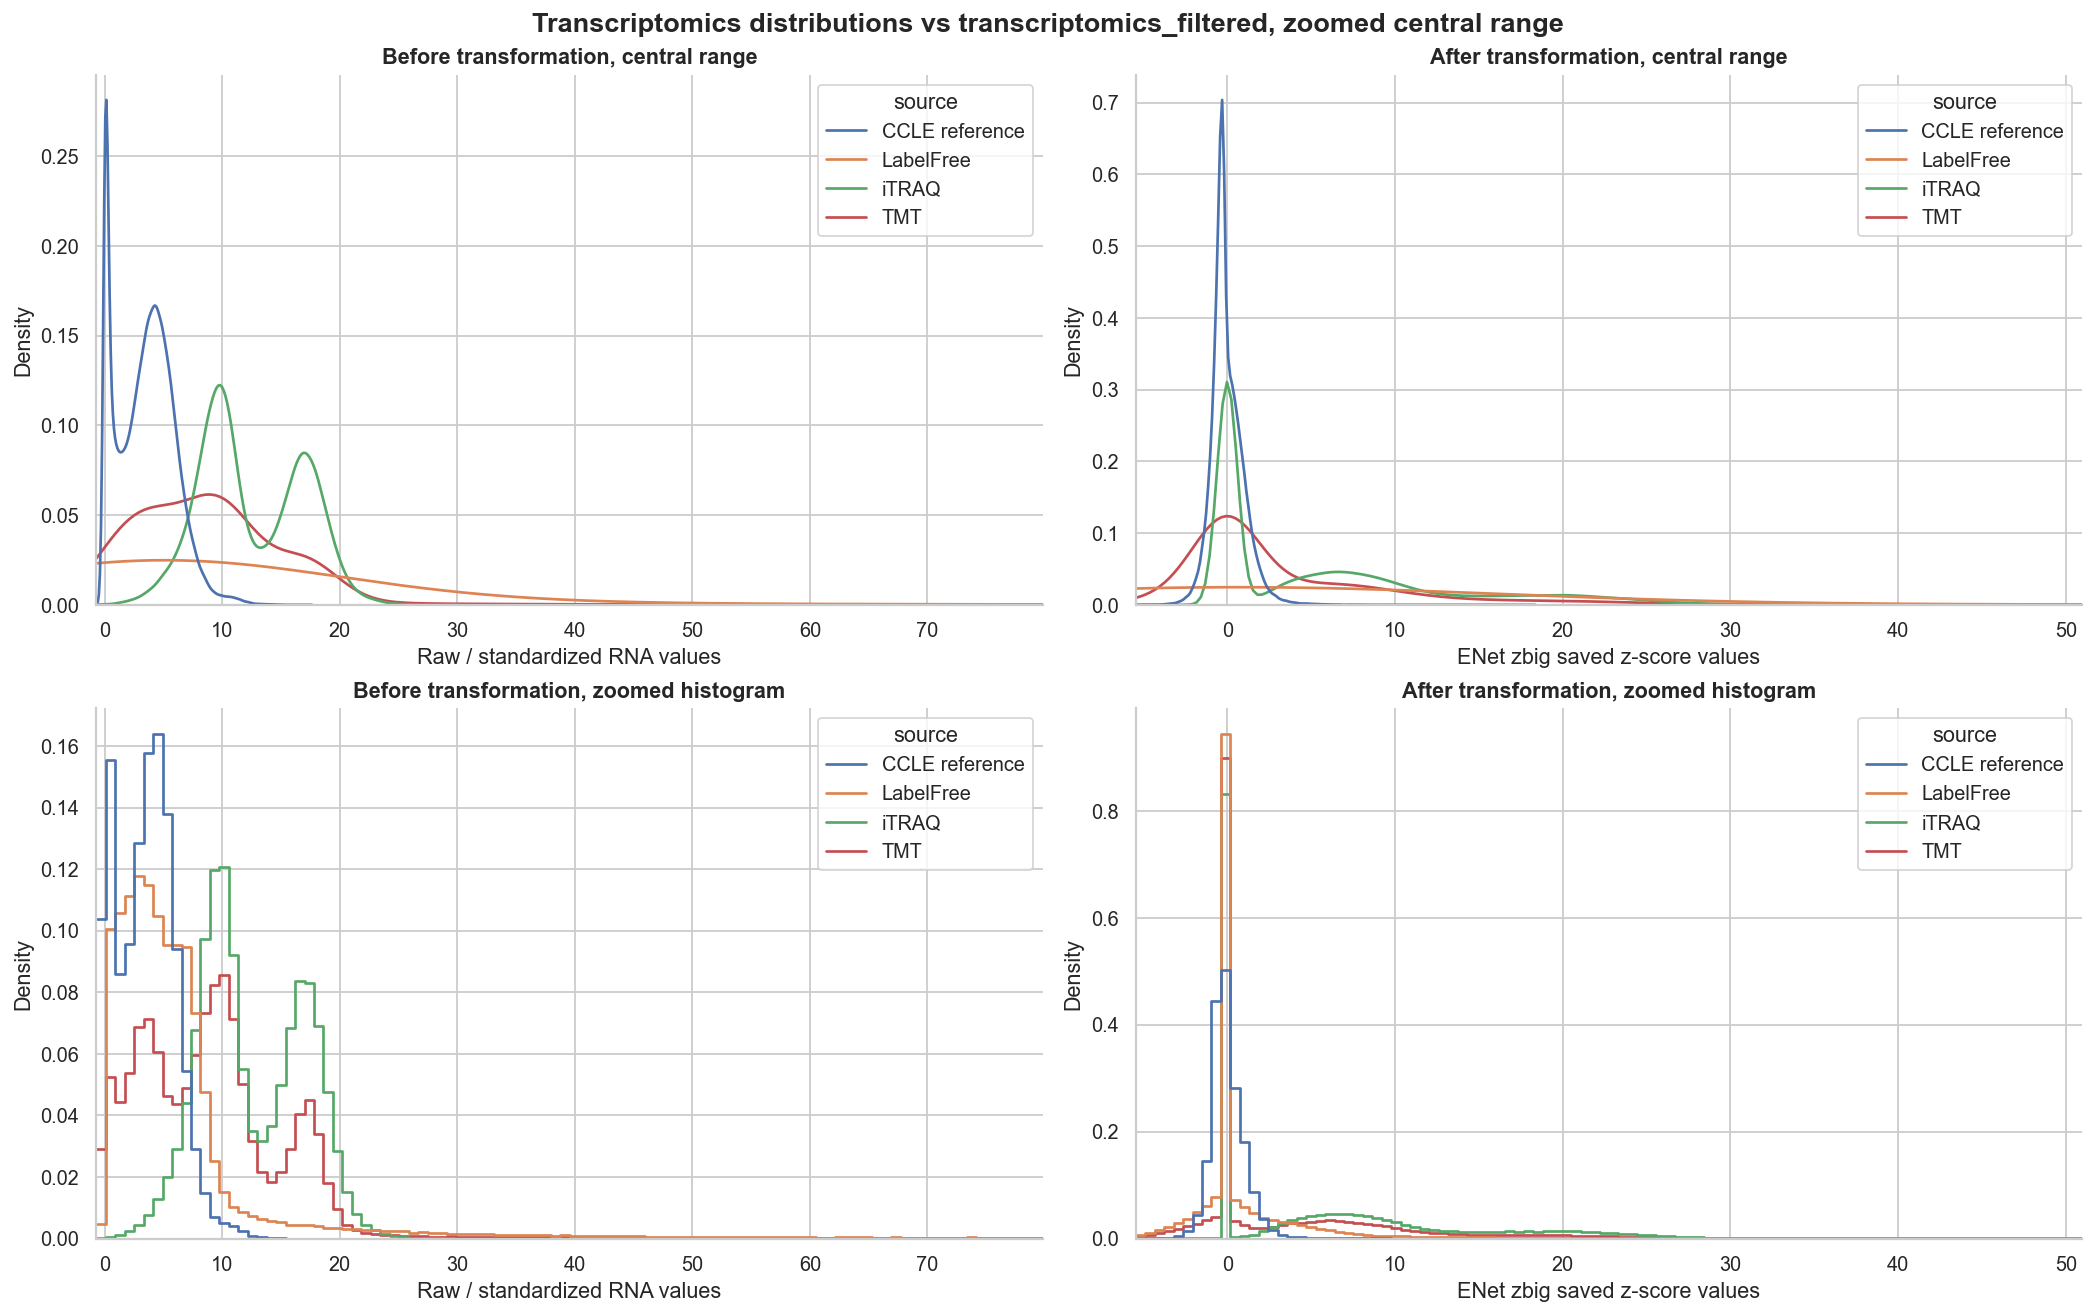

Saved plot: C:\Users\hp\Desktop\new_pRNA\val_data_enet_zbig\plots\transcriptomics_before_after_enet_zbig_zscore_zoomed.png


,stage,source,n,mean,std,min,q001,q005,q01,median,q99,q995,q999,max
0,after,CCLE reference,250000,0.000369,0.999256,-7.168662,-3.300582,-2.461565,-2.115658,-0.191751,2.982315,3.721581,5.938568,18.132071
1,after,LabelFree,250000,6.363996,185.076579,-16.892984,-8.228841,-5.937570,-4.977657,0.000000,81.272098,157.834381,736.126646,37935.738281
2,after,TMT,250000,3.885755,23.840467,-23.468937,-12.120412,-8.142218,-6.200679,0.000000,28.482480,45.183579,173.569999,4686.770508
3,after,iTRAQ,250000,5.741709,7.259733,-12.990215,0.000000,0.000000,0.000000,3.115404,26.464027,28.335381,32.400098,44.278748
4,before,CCLE reference,250000,3.469380,2.410444,0.000000,0.000000,0.000000,0.000000,3.576522,9.822987,10.876068,12.342697,17.032315
5,before,LabelFree,250000,12.778951,176.836838,0.003000,0.036000,0.099000,0.160000,4.680000,125.591420,237.775495,895.317685,42109.600000
6,before,TMT,250000,9.712887,28.224480,-9.340000,-4.008000,-2.361000,-1.528010,8.500000,37.522050,62.109035,239.654445,6323.046000
7,before,iTRAQ,250000,12.512064,4.418018,-2.123434,1.252170,2.889875,3.727868,11.365761,21.569030,22.540010,24.611001,29.005000


In [14]:
# ============================================================
# Better zoomed transcriptomics distribution plots
# Replaces the previous transcriptomics plotting block only
# ============================================================

rng = np.random.default_rng(RANDOM_SEED)

def sample_numeric_values(df, max_values=MAX_VALUES_PER_DISTRIBUTION, random_state=RANDOM_SEED):
    if df is None or df.empty:
        return np.array([], dtype=float)
    arr = df.to_numpy(dtype=float, copy=False).ravel()
    arr = arr[np.isfinite(arr)]
    if arr.size > max_values:
        rng_local = np.random.default_rng(random_state)
        idx = rng_local.choice(arr.size, size=max_values, replace=False)
        arr = arr[idx]
    return arr


def make_distribution_frame(reference_df, validation_dict, modality_label):
    rows = []

    ref_vals = sample_numeric_values(reference_df)
    if ref_vals.size:
        rows.append(
            pd.DataFrame({
                "value": ref_vals,
                "source": "CCLE reference",
                "dataset": "CCLE",
                "modality": modality_label,
            })
        )

    for group, df in validation_dict.items():
        vals = sample_numeric_values(df)
        if vals.size:
            rows.append(
                pd.DataFrame({
                    "value": vals,
                    "source": group,
                    "dataset": group,
                    "modality": modality_label,
                })
            )

    if not rows:
        return pd.DataFrame(columns=["value", "source", "dataset", "modality"])

    return pd.concat(rows, ignore_index=True)


def clipped_for_zoom(df, lower_q=0.005, upper_q=0.995):
    """
    Keep the central distribution only, so KDE is not flattened by extreme tails.
    """
    if df.empty:
        return df.copy()

    lo, hi = df["value"].quantile([lower_q, upper_q])
    out = df[df["value"].between(lo, hi)].copy()

    print(f"Zoom limits from quantiles {lower_q:.3f}-{upper_q:.3f}: [{lo:.4f}, {hi:.4f}]")
    print(f"Rows before zoom: {len(df):,}; after zoom: {len(out):,}")

    return out


def plot_zoomed_transcriptomics_distributions(
    before_df,
    after_df,
    out_path,
    lower_q=0.005,
    upper_q=0.995,
):
    before_zoom = clipped_for_zoom(before_df, lower_q=lower_q, upper_q=upper_q)
    after_zoom = clipped_for_zoom(after_df, lower_q=lower_q, upper_q=upper_q)

    fig, axes = plt.subplots(2, 2, figsize=(16, 10), constrained_layout=True)

    # Raw full range, but with robust x-limits
    before_lo, before_hi = before_df["value"].quantile([lower_q, upper_q])
    after_lo, after_hi = after_df["value"].quantile([lower_q, upper_q])

    sns.kdeplot(
        data=before_df,
        x="value",
        hue="source",
        common_norm=False,
        fill=False,
        ax=axes[0, 0],
        linewidth=1.5,
        clip=(before_lo, before_hi),
    )
    axes[0, 0].set_xlim(before_lo, before_hi)
    axes[0, 0].set_title("Before transformation, central range")
    axes[0, 0].set_xlabel("Raw / standardized RNA values")
    axes[0, 0].set_ylabel("Density")

    sns.kdeplot(
        data=after_df,
        x="value",
        hue="source",
        common_norm=False,
        fill=False,
        ax=axes[0, 1],
        linewidth=1.5,
        clip=(after_lo, after_hi),
    )
    axes[0, 1].set_xlim(after_lo, after_hi)
    axes[0, 1].set_title("After transformation, central range")
    axes[0, 1].set_xlabel("ENet zbig saved z-score values")
    axes[0, 1].set_ylabel("Density")

    # Same data as histograms; often easier to inspect than KDE with spikes
    sns.histplot(
        data=before_zoom,
        x="value",
        hue="source",
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        bins=100,
        ax=axes[1, 0],
    )
    axes[1, 0].set_xlim(before_lo, before_hi)
    axes[1, 0].set_title("Before transformation, zoomed histogram")
    axes[1, 0].set_xlabel("Raw / standardized RNA values")
    axes[1, 0].set_ylabel("Density")

    sns.histplot(
        data=after_zoom,
        x="value",
        hue="source",
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        bins=100,
        ax=axes[1, 1],
    )
    axes[1, 1].set_xlim(after_lo, after_hi)
    axes[1, 1].set_title("After transformation, zoomed histogram")
    axes[1, 1].set_xlabel("ENet zbig saved z-score values")
    axes[1, 1].set_ylabel("Density")

    fig.suptitle(
        "Transcriptomics distributions vs transcriptomics_filtered, zoomed central range",
        fontsize=15,
        fontweight="bold",
    )

    fig.savefig(out_path, bbox_inches="tight", dpi=160)
    plt.show()
    print("Saved plot:", out_path)

    summary = (
        pd.concat([
            before_df.assign(stage="before"),
            after_df.assign(stage="after"),
        ], ignore_index=True)
        .groupby(["stage", "source"])["value"]
        .agg(
            n="count",
            mean="mean",
            std="std",
            min="min",
            q001=lambda x: x.quantile(0.001),
            q005=lambda x: x.quantile(0.005),
            q01=lambda x: x.quantile(0.01),
            median="median",
            q99=lambda x: x.quantile(0.99),
            q995=lambda x: x.quantile(0.995),
            q999=lambda x: x.quantile(0.999),
            max="max",
        )
        .reset_index()
    )

    display(summary)

    return before_zoom, after_zoom, summary


# ============================================================
# RNA before: raw Collection A RNA vs raw CCLE transcriptomics_filtered
# on overlapping genes
# ============================================================

rna_before_validation = {}
common_reference_rna_cols = set(ccle_rna.columns.astype(str))

for group in GROUPS:
    raw = transformed_store.get(group, {}).get("RNA_raw")
    if raw is None:
        continue

    raw = raw.copy()
    raw.columns = raw.columns.astype(str)

    common = [c for c in raw.columns if c in common_reference_rna_cols]
    if common:
        rna_before_validation[group] = raw.reindex(columns=common)

rna_before_ref_cols = (
    sorted(set().union(*[set(df.columns) for df in rna_before_validation.values()]))
    if rna_before_validation
    else []
)

rna_before_ref = ccle_rna.copy()
rna_before_ref.columns = rna_before_ref.columns.astype(str)
rna_before_ref = rna_before_ref.reindex(columns=rna_before_ref_cols)

# ============================================================
# RNA after: apply the same representative ENet normalizer to CCLE reference,
# compare with saved transformed validation RNA
# ============================================================

rna_after_ref = apply_saved_zscore_normalizer(
    ccle_rna,
    representative_normalizer,
    fill_missing_z=0.0,
)

rna_after_validation = {
    group: transformed_store[group]["RNA"]
    for group in transformed_store
    if "RNA" in transformed_store[group]
}

rna_before_df = make_distribution_frame(
    rna_before_ref,
    rna_before_validation,
    "RNA before",
)

rna_after_df = make_distribution_frame(
    rna_after_ref,
    rna_after_validation,
    "RNA after",
)

rna_before_zoom, rna_after_zoom, rna_distribution_summary = plot_zoomed_transcriptomics_distributions(
    rna_before_df,
    rna_after_df,
    out_path=PLOTS_DIR / "transcriptomics_before_after_enet_zbig_zscore_zoomed.png",
    lower_q=0.005,
    upper_q=0.995,
)

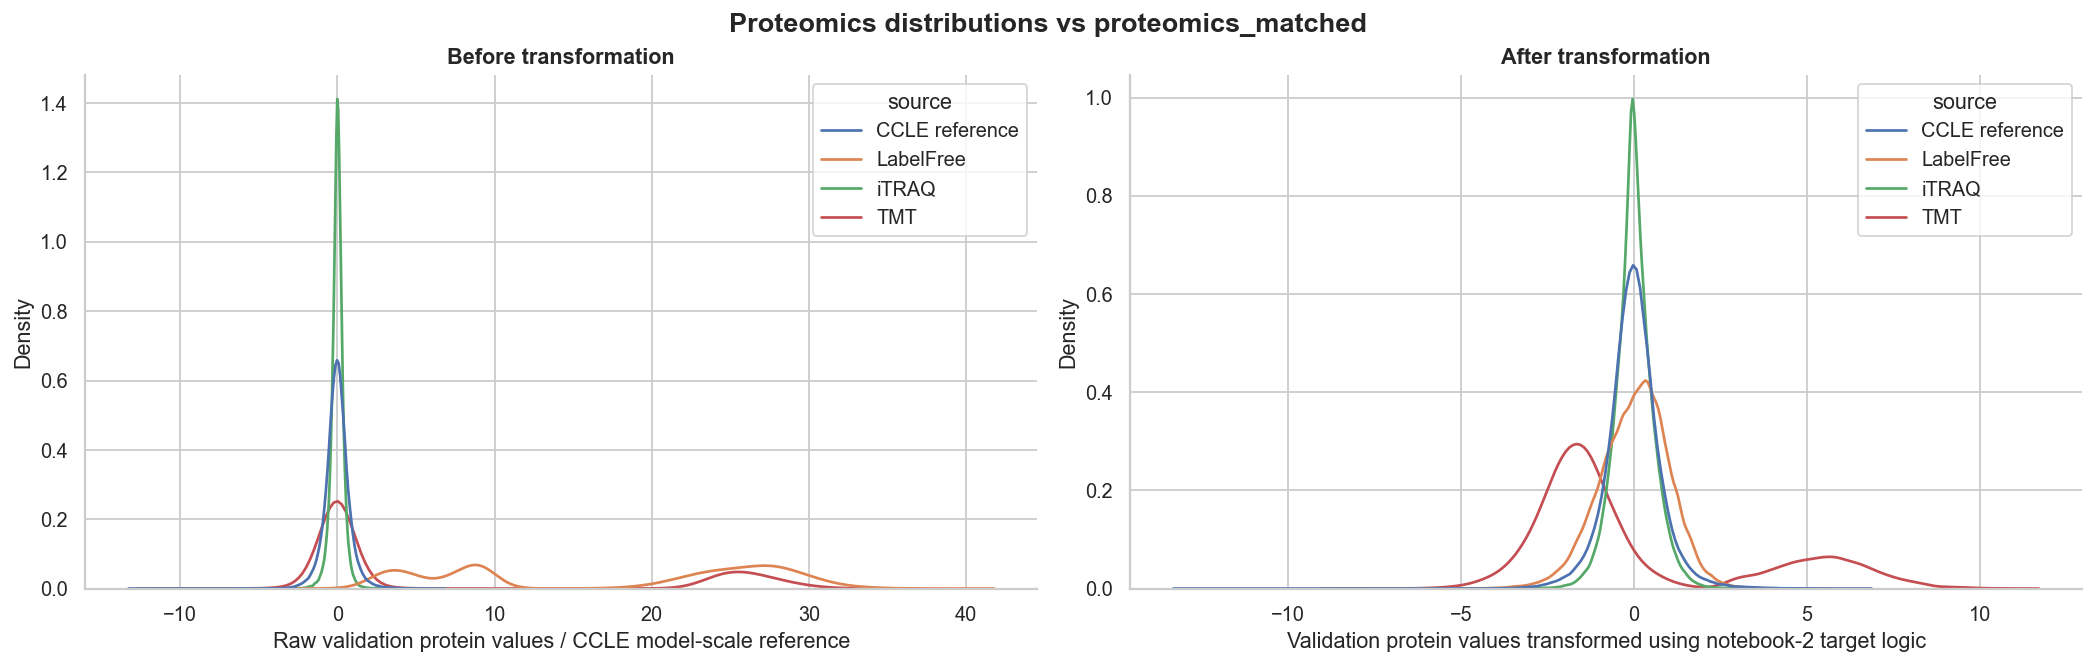

Saved plot: C:\Users\hp\Desktop\new_pRNA\val_data_enet_zbig\plots\proteomics_before_after_enet_zbig_targets_no_zoom.png


,stage,source,n,mean,std,min,q001,q01,median,q99,q999,max
0,after,CCLE reference,250000,-0.021540,0.780961,-13.101331,-3.274438,-2.114404,-0.022706,2.136105,3.659677,6.665530
1,after,LabelFree,250000,0.014971,1.004164,-7.321084,-3.754918,-2.563953,0.075863,2.245273,3.166440,4.654992
2,after,TMT,250000,0.007981,3.265573,-8.245863,-5.589382,-4.378859,-1.275837,8.015328,9.547908,10.874632
3,after,iTRAQ,250000,0.000835,0.560927,-4.333742,-2.206131,-1.446538,-0.011600,1.475424,2.191363,4.210231
4,before,CCLE reference,250000,-0.021540,0.780961,-13.101331,-3.274438,-2.114404,-0.022706,2.136105,3.659677,6.665530
5,before,LabelFree,250000,17.599438,10.254862,0.000000,0.030000,1.779000,22.227000,32.660000,35.230001,39.208000
6,before,TMT,250000,6.727528,11.501205,-9.824000,-4.311001,-2.194000,0.198000,29.842010,31.726001,34.035000
7,before,iTRAQ,250000,-0.008697,0.401652,-6.357000,-2.036603,-1.179000,0.002000,1.035000,1.809002,5.210000


In [15]:
# ============================================================
# Proteomics distribution plots, no zoom
# Raw Collection A proteins vs proteomics_matched
# ============================================================

rng = np.random.default_rng(RANDOM_SEED)

def sample_numeric_values(df, max_values=MAX_VALUES_PER_DISTRIBUTION, random_state=RANDOM_SEED):
    if df is None or df.empty:
        return np.array([], dtype=float)
    arr = df.to_numpy(dtype=float, copy=False).ravel()
    arr = arr[np.isfinite(arr)]
    if arr.size > max_values:
        rng_local = np.random.default_rng(random_state)
        idx = rng_local.choice(arr.size, size=max_values, replace=False)
        arr = arr[idx]
    return arr


def make_distribution_frame(reference_df, validation_dict, modality_label):
    rows = []

    ref_vals = sample_numeric_values(reference_df)
    if ref_vals.size:
        rows.append(
            pd.DataFrame({
                "value": ref_vals,
                "source": "CCLE reference",
                "dataset": "CCLE",
                "modality": modality_label,
            })
        )

    for group, df in validation_dict.items():
        vals = sample_numeric_values(df)
        if vals.size:
            rows.append(
                pd.DataFrame({
                    "value": vals,
                    "source": group,
                    "dataset": group,
                    "modality": modality_label,
                })
            )

    if not rows:
        return pd.DataFrame(columns=["value", "source", "dataset", "modality"])

    return pd.concat(rows, ignore_index=True)


def plot_proteomics_distributions_no_zoom(before_df, after_df, out_path):
    fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)

    sns.kdeplot(
        data=before_df,
        x="value",
        hue="source",
        common_norm=False,
        fill=False,
        ax=axes[0],
        linewidth=1.5,
    )
    axes[0].set_title("Before transformation")
    axes[0].set_xlabel("Raw validation protein values / CCLE model-scale reference")
    axes[0].set_ylabel("Density")

    sns.kdeplot(
        data=after_df,
        x="value",
        hue="source",
        common_norm=False,
        fill=False,
        ax=axes[1],
        linewidth=1.5,
    )
    axes[1].set_title("After transformation")
    axes[1].set_xlabel("Validation protein values transformed using notebook-2 target logic")
    axes[1].set_ylabel("Density")

    fig.suptitle(
        "Proteomics distributions vs proteomics_matched",
        fontsize=15,
        fontweight="bold",
    )

    fig.savefig(out_path, bbox_inches="tight", dpi=160)
    plt.show()
    print("Saved plot:", out_path)

    summary = (
        pd.concat([
            before_df.assign(stage="before"),
            after_df.assign(stage="after"),
        ], ignore_index=True)
        .groupby(["stage", "source"])["value"]
        .agg(
            n="count",
            mean="mean",
            std="std",
            min="min",
            q001=lambda x: x.quantile(0.001),
            q01=lambda x: x.quantile(0.01),
            median="median",
            q99=lambda x: x.quantile(0.99),
            q999=lambda x: x.quantile(0.999),
            max="max",
        )
        .reset_index()
    )

    display(summary)
    return summary


# ============================================================
# Protein before/after dataframes
# ============================================================

protein_before_validation = {}
protein_after_validation = {}
all_matching = set()

for group in GROUPS:
    raw = transformed_store.get(group, {}).get("Protein_raw")
    aft = transformed_store.get(group, {}).get("Protein")

    if raw is None or aft is None:
        continue

    raw = raw.copy()
    aft = aft.copy()

    raw.columns = raw.columns.astype(str)
    aft.columns = aft.columns.astype(str)

    common = sorted(set(raw.columns).intersection(set(aft.columns)))
    if not common:
        continue

    protein_before_validation[group] = raw.reindex(columns=common)
    protein_after_validation[group] = aft.reindex(columns=common)
    all_matching.update(common)

protein_ref = ccle_prot.copy()
protein_ref.columns = protein_ref.columns.astype(str)
protein_ref = protein_ref.reindex(columns=sorted(all_matching))

protein_before_df = make_distribution_frame(
    protein_ref,
    protein_before_validation,
    "Protein before",
)

protein_after_df = make_distribution_frame(
    protein_ref,
    protein_after_validation,
    "Protein after",
)

protein_distribution_summary = plot_proteomics_distributions_no_zoom(
    protein_before_df,
    protein_after_df,
    out_path=PLOTS_DIR / "proteomics_before_after_enet_zbig_targets_no_zoom.png",
)

## 7. Saved-file summary

In [13]:

print("Files ready for notebook 7.5:")
for p in sorted(VAL_OUT_DIR.glob("*.joblib")):
    print("-", p.name)
print("\nMetadata:")
for p in sorted(VAL_OUT_DIR.glob("*.csv")):
    print("-", p.name)
print("- manifest_enet_zbig_transform.json")
print("\nPlots:")
for p in sorted(PLOTS_DIR.glob("*.png")):
    print("-", p.name)

print("\nUse this folder in notebook 7.5:")
print(VAL_OUT_DIR.resolve())


Files ready for notebook 7.5:
- iTRAQ_proteomics.joblib
- iTRAQ_proteomics_raw.joblib
- iTRAQ_transcriptomics.joblib
- iTRAQ_transcriptomics_raw.joblib
- LabelFree_proteomics.joblib
- LabelFree_proteomics_raw.joblib
- LabelFree_transcriptomics.joblib
- LabelFree_transcriptomics_raw.joblib
- normalizer_reference.joblib
- TMT_proteomics.joblib
- TMT_proteomics_raw.joblib
- TMT_transcriptomics.joblib
- TMT_transcriptomics_raw.joblib

Metadata:
- enet_zbig_model_inventory.csv
- matching_proteins_by_dataset.csv
- normalizer_reference_table.csv
- normalizer_scan_summary.csv
- manifest_enet_zbig_transform.json

Plots:
- proteomics_before_after_enet_zbig_targets.png
- transcriptomics_before_after_enet_zbig_zscore.png

Use this folder in notebook 7.5:
C:\Users\hp\Desktop\new_pRNA\val_data_enet_zbig
